# 07 · Validación final y casos reales

Se evalúan, una sola vez, los dos modelos finales congelados en el notebook
06 — el interpretable y el de potencia bruta — sobre **tres conjuntos de
validación externa genuina**:

1. **Delaney/ESOL** — sin solapamiento con el entrenamiento.
2. **Second Solubility Challenge — `tight`** (100 moléculas, alta calidad experimental).
3. **Second Solubility Challenge — `loose`** (32 moléculas, alta varianza experimental).

El objetivo final es ubicar ambos modelos frente a los benchmarks publicados
por Conn et al. (2023) para el SC-2, sin haber tocado estos conjuntos en
ninguna etapa anterior del pipeline.

La evaluación externa utiliza conjuntos de procedencia documentada: ESOL, descrito por Delaney (2004), y los conjuntos `tight` y `loose` del Second Solubility Challenge, analizados por Conn et al. (2023). Estos datos se emplean exclusivamente para evaluar y reportar el rendimiento de los modelos finales.

Configuración global cargada
Semilla: 1
RESUMEN DE LOS CONJUNTOS DE DATOS

Entrenamiento (AqSolDB, depurado)
  Moléculas: 6,592
  logS: [-12.06, 1.97]  media=-2.929  sd=2.359

Validación interna (AqSolDB, SD=0)
  Moléculas: 1,316
  logS: [-13.17, 2.14]  media=-2.975  sd=2.411

Validación externa1 (Delaney/ESOL)
  Moléculas: 1,128
  logS: [-11.60, 1.58]  media=-3.050  sd=2.096

Validación externa2 (Tight_SC-2)
  Moléculas: 100
  logS: [-6.79, -1.18]  media=-4.027  sd=1.272

Validación externa3 (Loose_SC-2)
  Moléculas: 32
  logS: [-10.40, -1.24]  media=-5.241  sd=2.176


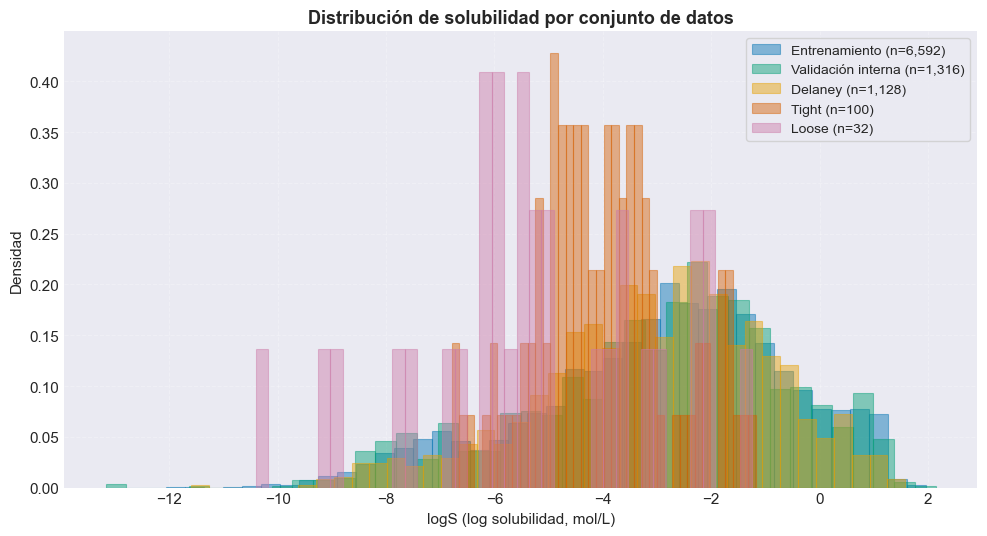

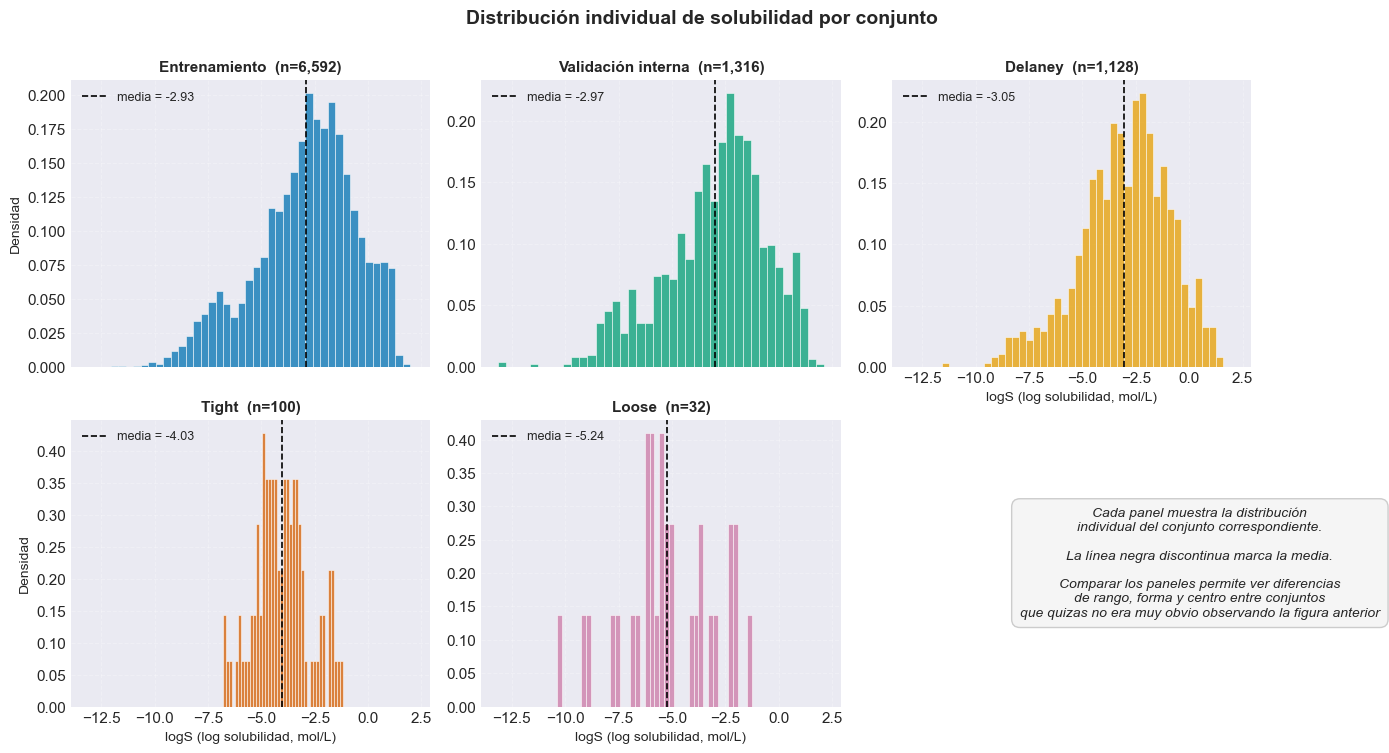

DECISION DE MODELOS FINALES (criterio: R2 de CV + tiempo de computo)

MODELO INTERPRETABLE
  Familia: LightGBM
  Features: 13 (consenso >= 3/4 familias, notebook 03)
  R2(CV): 0.8273
  Razon: gana el más rápido: diferencia de R² (0.0034) menor que 1 SD de CV del más lento (0.0066)

MODELO DE POTENCIA BRUTA
  Familia: LightGBM
  Features: 29 (k optimo propio de LightGBM, notebook 03)
  R2(CV): 0.8502
  Razon: gana el más rápido: diferencia de R² (-0.0024) menor que 1 SD de CV del más lento (0.0067)

Ninguna decision se tomo mirando la validacion externa (Delaney)
ese se reservan para el notebook 07, con fines
exclusivamente de reporte.



In [1]:
%run 02_configuracion_y_datos.ipynb

modelo_interpretable = joblib.load('../resultados/modelos_finales/modelo_interpretable.pkl')
modelo_bruto = joblib.load('../resultados/modelos_finales/modelo_potencia_bruta.pkl')
features_interpretable = joblib.load('../resultados/modelos_finales/features_interpretable.pkl')
features_bruto = joblib.load('../resultados/modelos_finales/features_potencia_bruta.pkl')

print(open('../resultados/decision_modelos_finales.txt').read())

In [2]:
# Carga explícita de los tres conjuntos de validación externa para evitar errores
df_validacion_externa   = pd.read_csv('../data/processed/df_delaney_complete.csv')
df_tight                = pd.read_csv('../data/processed/df_tight_complete.csv')
df_loose                = pd.read_csv('../data/processed/df_loose_complete.csv')

# Verificación rápida
print(f"Delaney:  {len(df_validacion_externa):,} moléculas  |  col='measured log solubility in mols per litre'")
print(f"Tight:    {len(df_tight):,} moléculas              |  col='Solubility'")
print(f"Loose:    {len(df_loose):,} moléculas              |  col= 'Solubility'")

Delaney:  1,128 moléculas  |  col='measured log solubility in mols per litre'
Tight:    100 moléculas              |  col='Solubility'
Loose:    32 moléculas              |  col= 'Solubility'


## 1 · Validación externa 1 — Delaney/ESOL

Primer conjunto de validación externa genuina. Se mantiene intacto desde el
preprocesamiento (notebook 01), sin solapamiento con el entrenamiento.

In [3]:
def evaluar(modelo, x, y):
    y_pred = modelo.predict(x)
    return {
        'r2': r2_score(y, y_pred),
        'mae': mean_absolute_error(y, y_pred),
        'rmse': np.sqrt(mean_squared_error(y, y_pred)),
        'y_pred': y_pred,
    }


def evaluar_en_conjunto(nombre_conjunto, df, col_y, modelos_features):
    """
    Evalúa todos los modelos sobre un conjunto y devuelve una lista de dicts,
    una fila por (modelo, conjunto).
    """
    y = df[col_y]
    filas = []
    for nombre, modelo, features in modelos_features:
        res = evaluar(modelo, df[features], y)
        filas.append({
            'conjunto': nombre_conjunto,
            'modelo': nombre,
            'n_features': len(features),
            'n_moleculas': len(df),
            'r2': res['r2'],
            'mae': res['mae'],
            'rmse': res['rmse'],
            'y_pred': res['y_pred'],
        })
    return filas


modelos_features = [
    ('Interpretable',  modelo_interpretable, features_interpretable),
    ('Potencia bruta', modelo_bruto,         features_bruto),
]

In [4]:
filas_externas = []

filas_externas += evaluar_en_conjunto(
    'Delaney',
    df_validacion_externa,
    'measured log solubility in mols per litre',
    modelos_features,
)

tabla_delaney = pd.DataFrame(
    [{k: v for k, v in f.items() if k != 'y_pred'} for f in filas_externas]
)
print(tabla_delaney.round(4).to_string(index=False))

conjunto         modelo  n_features  n_moleculas     r2    mae   rmse
 Delaney  Interpretable          13         1128 0.8857 0.5263 0.7085
 Delaney Potencia bruta          29         1128 0.9052 0.4684 0.6450


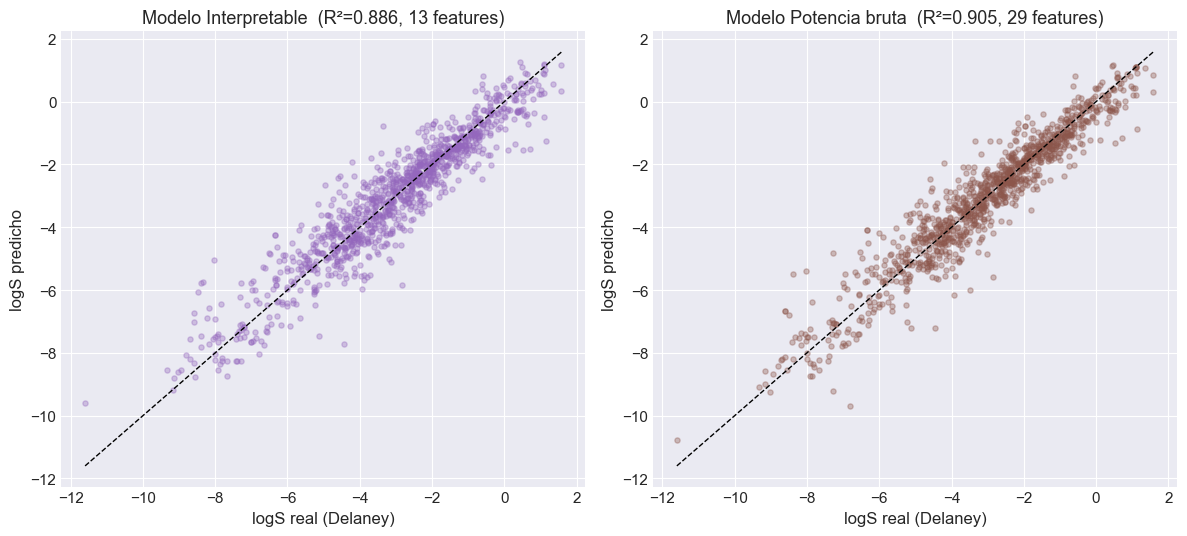

In [5]:
resultado_interpretable = evaluar(
    modelo_interpretable,
    df_validacion_externa[features_interpretable],
    df_validacion_externa['measured log solubility in mols per litre'],
)
resultado_bruto = evaluar(
    modelo_bruto,
    df_validacion_externa[features_bruto],
    df_validacion_externa['measured log solubility in mols per litre'],
)
y_externa = df_validacion_externa['measured log solubility in mols per litre']

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, resultado, nombre, color in [
    (axes[0], resultado_interpretable, 'Interpretable', COLORES['Interpretable']),
    (axes[1], resultado_bruto,         'Potencia bruta', COLORES['Potencia bruta']),
]:
    ax.scatter(y_externa, resultado['y_pred'], alpha=0.35, s=14, color=color)
    lims = [y_externa.min(), y_externa.max()]
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_xlabel('logS real (Delaney)')
    ax.set_ylabel('logS predicho')
    n_feat = tabla_delaney[tabla_delaney['modelo'] == nombre]['n_features'].values[0]
    ax.set_title(f"Modelo {nombre}  (R²={resultado['r2']:.3f}, {n_feat} features)")

plt.tight_layout()
os.makedirs('../resultados/graficos', exist_ok=True)
plt.savefig('../resultados/graficos/09_validacion_final_delaney.png', dpi=150)
plt.show()

## 2 · Validación externa 2 — Second Solubility Challenge (tight)

El conjunto `tight` del SC-2 contiene 100 moléculas con datos experimentales
de alta calidad (desviación estándar experimental ~0.17 unidades log). Se
usa aquí como **validación ciega**: en el notebook 01 se filtró cualquier
molécula de AqSolDB que coincidiera por InChIKey con este conjunto, de modo
que el modelo nunca vio estas moléculas durante el entrenamiento.

Referencia de comparación: Conn et al. (2023), *J. Chem. Inf. Model.*,
63, 1099–1113 (Tabla 3).ipynb_checkpoints/

In [6]:
faltan_tight = set(features_interpretable) - set(df_tight.columns)
faltan_tight |= set(features_bruto) - set(df_tight.columns)
assert not faltan_tight, f"Faltan features en df_tight: {faltan_tight}"

print(f"Rango de solubilidad en tight: "
      f"[{df_tight['Solubility'].min():.2f}, "
      f"{df_tight['Solubility'].max():.2f}]")
print(f"n moléculas en tight: {len(df_tight)}")

Rango de solubilidad en tight: [-6.79, -1.18]
n moléculas en tight: 100


In [7]:
filas_externas += evaluar_en_conjunto(
    'SC-2 tight',
    df_tight,
    'Solubility',
    modelos_features,
)

tabla_tight = pd.DataFrame(
    [{k: v for k, v in f.items() if k != 'y_pred'} for f in filas_externas
     if f['conjunto'] == 'SC-2 tight']
)
print(tabla_tight.round(4).to_string(index=False))

  conjunto         modelo  n_features  n_moleculas     r2    mae   rmse
SC-2 tight  Interpretable          13          100 0.3995 0.7973 0.9810
SC-2 tight Potencia bruta          29          100 0.3906 0.7654 0.9882


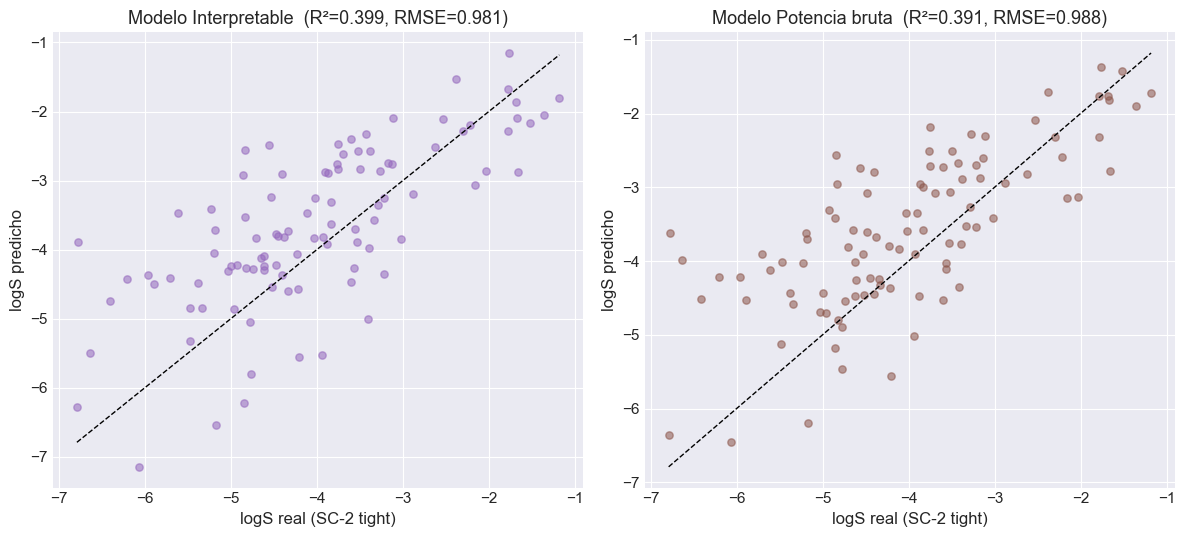

In [8]:
y_tight = df_tight['Solubility']
res_int_tight = evaluar(modelo_interpretable, df_tight[features_interpretable], y_tight)
res_bru_tight = evaluar(modelo_bruto,         df_tight[features_bruto],         y_tight)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, resultado, nombre, color in [
    (axes[0], res_int_tight, 'Interpretable', COLORES['Interpretable']),
    (axes[1], res_bru_tight, 'Potencia bruta', COLORES['Potencia bruta']),
]:
    ax.scatter(y_tight, resultado['y_pred'], alpha=0.55, s=28, color=color)
    lims = [y_tight.min(), y_tight.max()]
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_xlabel('logS real (SC-2 tight)')
    ax.set_ylabel('logS predicho')
    ax.set_title(f"Modelo {nombre}  (R²={resultado['r2']:.3f}, RMSE={resultado['rmse']:.3f})")

plt.tight_layout()
plt.savefig('../resultados/graficos/10_validacion_final_tight.png', dpi=150)
plt.show()

## 3 · Validación externa 3 — Second Solubility Challenge (loose)

El conjunto `loose` contiene 32 moléculas con datos experimentales de menor
calidad (desviación estándar ~0.62 unidades log). Es conocido en la
literatura como un conjunto mucho más difícil: la mayoría de los modelos del
estado del arte rinden significativamente peor aquí que en `tight`. Se
reporta como validación complementaria, no como métrica principal.
La interpretación de este conjunto como una evaluación complementaria debe considerar tanto su tamaño reducido como la mayor variabilidad experimental descrita para el SC-2 (Conn et al., 2023).

In [9]:
faltan_loose = set(features_interpretable) - set(df_loose.columns)
faltan_loose |= set(features_bruto) - set(df_loose.columns)
assert not faltan_loose, f"Faltan features en df_loose: {faltan_loose}"

print(f"Rango de solubilidad en loose: "
      f"[{df_loose['Solubility'].min():.2f}, "
      f"{df_loose['Solubility'].max():.2f}]")
print(f"n moléculas en loose: {len(df_loose)}")

filas_externas += evaluar_en_conjunto(
    'SC-2 loose',
    df_loose,
    'Solubility',
    modelos_features,
)

tabla_loose = pd.DataFrame(
    [{k: v for k, v in f.items() if k != 'y_pred'} for f in filas_externas
     if f['conjunto'] == 'SC-2 loose']
)
print(tabla_loose.round(4).to_string(index=False))

Rango de solubilidad en loose: [-10.40, -1.24]
n moléculas en loose: 32
  conjunto         modelo  n_features  n_moleculas     r2    mae   rmse
SC-2 loose  Interpretable          13           32 0.5738 1.1230 1.3983
SC-2 loose Potencia bruta          29           32 0.4884 1.1504 1.5319


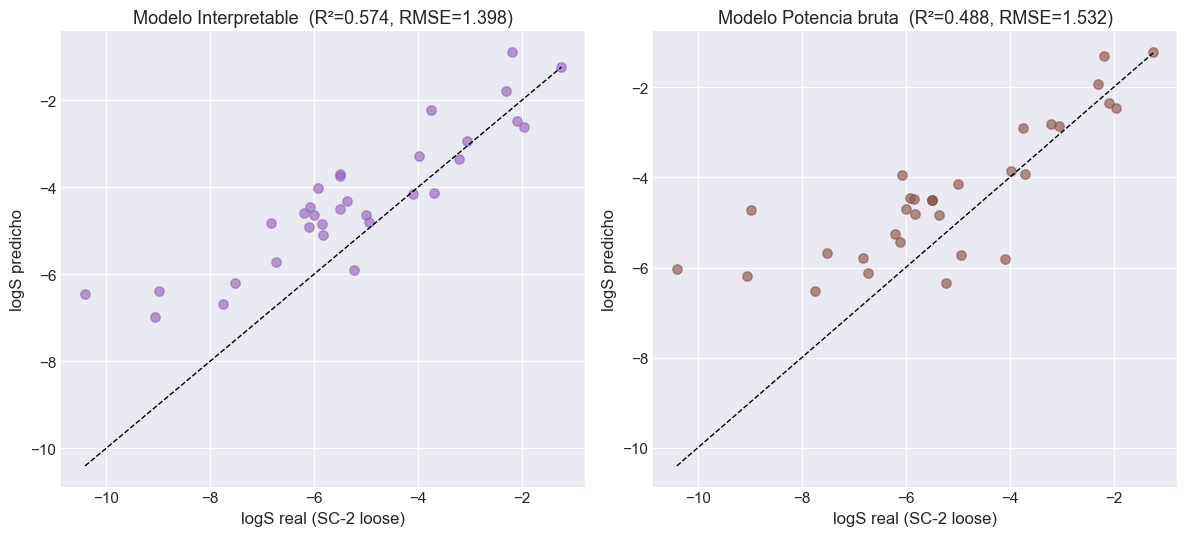

In [10]:
y_loose = df_loose['Solubility']
res_int_loose = evaluar(modelo_interpretable, df_loose[features_interpretable], y_loose)
res_bru_loose = evaluar(modelo_bruto,         df_loose[features_bruto],         y_loose)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, resultado, nombre, color in [
    (axes[0], res_int_loose, 'Interpretable', COLORES['Interpretable']),
    (axes[1], res_bru_loose, 'Potencia bruta', COLORES['Potencia bruta']),
]:
    ax.scatter(y_loose, resultado['y_pred'], alpha=0.65, s=45, color=color)
    lims = [y_loose.min(), y_loose.max()]
    ax.plot(lims, lims, 'k--', linewidth=1)
    ax.set_xlabel('logS real (SC-2 loose)')
    ax.set_ylabel('logS predicho')
    ax.set_title(f"Modelo {nombre}  (R²={resultado['r2']:.3f}, RMSE={resultado['rmse']:.3f})")

plt.tight_layout()
plt.savefig('../resultados/graficos/11_validacion_final_loose.png', dpi=150)
plt.show()

## 4 · Tabla consolidada y comparación con el estado del arte

Se reúnen los resultados de los tres conjuntos de validación externa en una
única tabla larga (una fila por modelo × conjunto). Se añade además una
tabla de referencia con los mejores modelos publicados por Conn et al.
(2023) para el SC-2, de modo que el lector pueda ubicar directamente el
rendimiento de los modelos propios frente a los benchmarks.

In [11]:
tabla_final = pd.DataFrame(
    [{k: v for k, v in f.items() if k != 'y_pred'} for f in filas_externas]
)

os.makedirs('../resultados/tablas', exist_ok=True)
tabla_final.to_csv('../resultados/tablas/validacion_final_completa.csv', index=False)

print(tabla_final.round(4).to_string(index=False))

  conjunto         modelo  n_features  n_moleculas     r2    mae   rmse
   Delaney  Interpretable          13         1128 0.8857 0.5263 0.7085
   Delaney Potencia bruta          29         1128 0.9052 0.4684 0.6450
SC-2 tight  Interpretable          13          100 0.3995 0.7973 0.9810
SC-2 tight Potencia bruta          29          100 0.3906 0.7654 0.9882
SC-2 loose  Interpretable          13           32 0.5738 1.1230 1.3983
SC-2 loose Potencia bruta          29           32 0.4884 1.1504 1.5319


## 5 · Prueba cualitativa: fármacos de uso común

Los valores de `logS_experimental` se calcularon a partir de la solubilidad
acuosa reportada en la fuente citada en la columna `fuente`, convertida a
mol/L con la masa molar del compuesto:

$$\log S = \log_{10}\left(\frac{\text{solubilidad (mg/mL)}}{\text{masa molar (g/mol)}}\right)$$

Todos los valores de LogS fueron calculados con la ecuación anterior a partir
de datos de masa molar y solubilidad en agua a 25 °C obtenidos de PubChem,
que a su vez hace referencia al *Hazardous Substances Data Bank*.

In [12]:
farmacos_datos = [
    ("Paracetamol", "CC(=O)NC1=CC=C(C=C1)O", 14, 151.16, -1.03, "PubChem"),
    ("Aspirina", "CC(=O)Oc1ccccc1C(=O)O", 4.6, 180.16, -1.59, "PubChem"),
    ("Ibuprofeno", "CC(C)CC1=CC=C(C=C1)C(C)C(=O)O", 0.021, 206.28, -3.99, "PubChem"),
    ("Naproxeno (Simple)", "CC(C1=CC=C2C=C(C=CC2=C1)C(=O)O)C", 0.0159, 230.26, -4.16, "PubChem"),
    ("Diazepam", "CN1C2=CC=C(C=C2C(=NCC1=O)C3=CC=CC=C3)Cl", 0.066, 284.74, -3.63, "PubChem"),
    ("Cafeína", "CN1C=NC2=C1C(=O)N(C(=O)N2C)C", 21.6, 194.19, -0.953, "PubChem"),
    ("Morfina", "CN1CCC23C4C1CC5=C2C(=C(C=C5)O)OC3C4O", 0.149, 285.34, -3.28, "PubChem"),
    ("Diclofenaco", "OC(=O)CC1=CC=CC=C1NC2=C(C=CC=C2Cl)Cl", 0.00237, 296.15, -5.09, "PubChem"),
    ("Atenolol", "CC(C)NCC(COC1=CC=C(C=C1)CC(=O)N)O", 13.3, 266.34, -1.3, "PubChem"),
    ("Captopril", "CC(C)(C)SCC(=O)N1CCCC1C(=O)O", 160.0, 217.29, -0.133, "PubChem"),
]

from rdkit import Chem
from rdkit.Chem import Descriptors


def calcular_descriptores(smiles, features):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    todos = pd.DataFrame([Descriptors.CalcMolDescriptors(mol)])
    return todos[[c for c in features if c in todos.columns]]


filas_farmacos = []
for nombre, smiles, mgml, masa_molar, logs_real, fuente in farmacos_datos:
    x_interp = calcular_descriptores(smiles, features_interpretable)
    x_bruto_f = calcular_descriptores(smiles, features_bruto)
    if x_interp is None:
        continue
    pred_interp = modelo_interpretable.predict(x_interp)[0]
    pred_bruto = modelo_bruto.predict(x_bruto_f)[0]
    filas_farmacos.append({
        'fármaco': nombre,
        'logS_experimental': round(logs_real, 3),
        'fuente': fuente,
        'logS_interpretable': round(pred_interp, 3),
        'error_interpretable': round(abs(logs_real - pred_interp), 3),
        'logS_potencia_bruta': round(pred_bruto, 3),
        'error_potencia_bruta': round(abs(logs_real - pred_bruto), 3),
    })

df_farmacos = pd.DataFrame(filas_farmacos)
print(df_farmacos.to_string(index=False))
df_farmacos.to_csv('../resultados/tablas/validacion_farmacos.csv', index=False)

           fármaco  logS_experimental  fuente  logS_interpretable  error_interpretable  logS_potencia_bruta  error_potencia_bruta
       Paracetamol             -1.030 PubChem              -1.694                0.664               -1.620                 0.590
          Aspirina             -1.590 PubChem              -2.090                0.500               -1.821                 0.231
        Ibuprofeno             -3.990 PubChem              -3.256                0.734               -3.233                 0.757
Naproxeno (Simple)             -4.160 PubChem              -4.013                0.147               -3.964                 0.196
          Diazepam             -3.630 PubChem              -4.151                0.521               -4.268                 0.638
           Cafeína             -0.953 PubChem              -1.435                0.482               -1.437                 0.484
           Morfina             -3.280 PubChem              -1.428                1.852    

## 6 · Precisión y error por fármaco (gráficas)

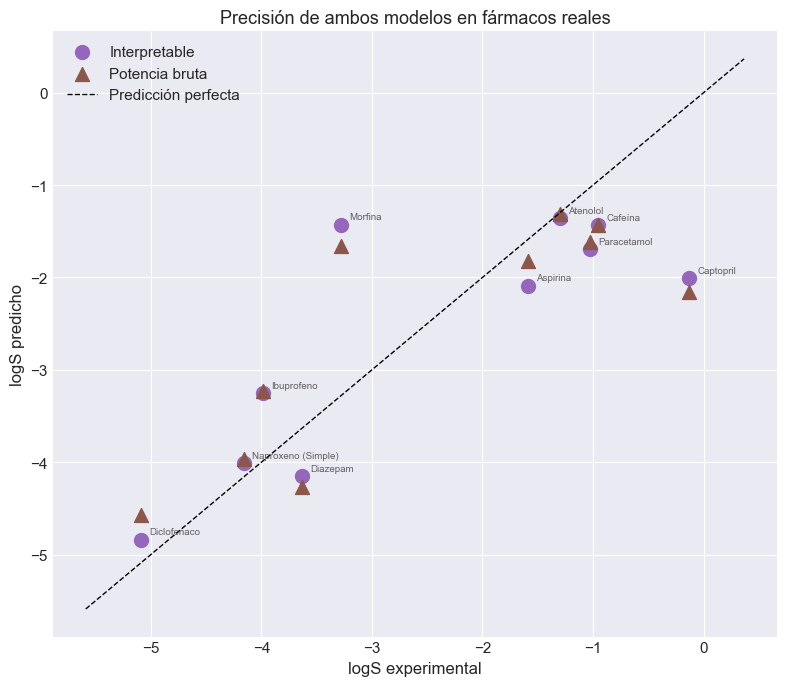

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df_farmacos['logS_experimental'], df_farmacos['logS_interpretable'],
           s=100, color=COLORES['Interpretable'], label='Interpretable', marker='o')
ax.scatter(df_farmacos['logS_experimental'], df_farmacos['logS_potencia_bruta'],
           s=100, color=COLORES['Potencia bruta'], label='Potencia bruta', marker='^')

for _, fila in df_farmacos.iterrows():
    ax.annotate(fila['fármaco'],
                (fila['logS_experimental'], fila['logS_interpretable']),
                textcoords="offset points", xytext=(6, 4), fontsize=7, alpha=0.7)

lims = [df_farmacos['logS_experimental'].min() - 0.5,
        df_farmacos['logS_experimental'].max() + 0.5]
ax.plot(lims, lims, 'k--', linewidth=1, label='Predicción perfecta')
ax.set_xlabel('logS experimental')
ax.set_ylabel('logS predicho')
ax.set_title('Precisión de ambos modelos en fármacos reales')
ax.legend()
plt.tight_layout()
plt.savefig('../resultados/graficos/12_precision_farmacos.png', dpi=150)
plt.show()

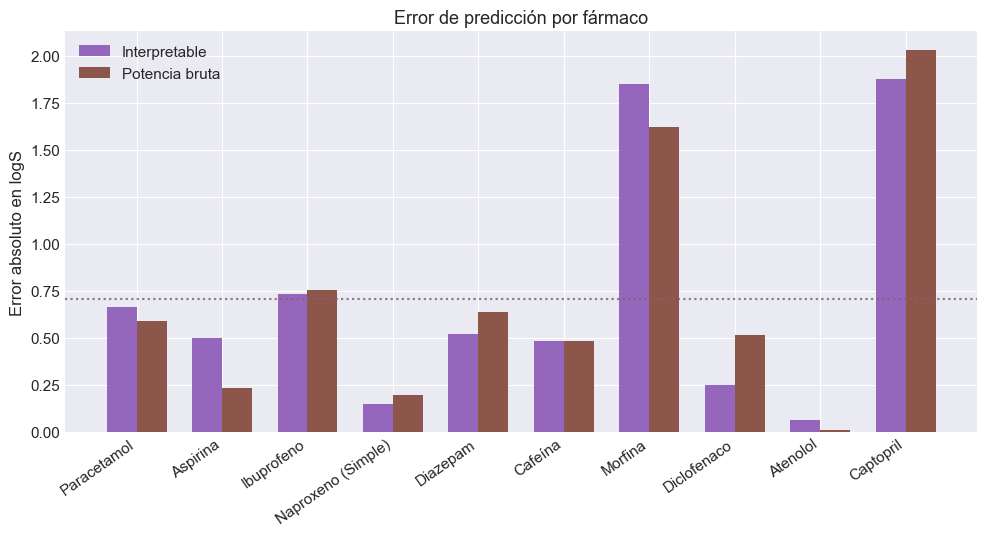

Error absoluto medio -- Interpretable: 0.709  Potencia bruta: 0.707


In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
x_pos = np.arange(len(df_farmacos))
ancho = 0.35

ax.bar(x_pos - ancho/2, df_farmacos['error_interpretable'], width=ancho,
       label='Interpretable', color=COLORES['Interpretable'])
ax.bar(x_pos + ancho/2, df_farmacos['error_potencia_bruta'], width=ancho,
       label='Potencia bruta', color=COLORES['Potencia bruta'])

ax.set_xticks(x_pos)
ax.set_xticklabels(df_farmacos['fármaco'], rotation=35, ha='right')
ax.set_ylabel('Error absoluto en logS')
ax.set_title('Error de predicción por fármaco')
ax.axhline(df_farmacos['error_interpretable'].mean(),
           color=COLORES['Interpretable'], linestyle=':', alpha=0.6)
ax.axhline(df_farmacos['error_potencia_bruta'].mean(),
           color=COLORES['Potencia bruta'], linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig('../resultados/graficos/13_error_farmacos.png', dpi=150)
plt.show()

print(f"Error absoluto medio -- Interpretable: {df_farmacos['error_interpretable'].mean():.3f}  "
      f"Potencia bruta: {df_farmacos['error_potencia_bruta'].mean():.3f}")

## 7 · Casos de error grande: hipótesis

Dos casos destacan por su error, en ambos modelos: **morfina** y
**captopril**.

- **Morfina** es un alcaloide con un sistema de anillos fusionados rígido y
  varios centros estereogénicos; los descriptores 2D usados aquí no
  distinguen estereoisómeros, y la rigidez conformacional de la molécula
  puede no estar bien capturada por descriptores topológicos simples.
- **Captopril** tiene un grupo tiol (-SH) libre, poco frecuente en el resto
  del conjunto de entrenamiento — es plausible que el modelo tenga poca
  señal de entrenamiento sobre cómo ese grupo funcional interactúa con el
  agua, y que los descriptores usados no capturen bien su comportamiento
  específico (el azufre en estado reducido tiene una química de solvatación
  distinta a la de los grupos oxigenados/nitrogenados dominantes en
  AqSolDB).

En ambos casos, la hipótesis compartida es la misma: cuando una molécula se
aleja de la química representada mayoritariamente en el set de
entrenamiento (grupos funcionales poco frecuentes, estereoquímica compleja),
el error crece — un límite esperable de cualquier modelo basado en
descriptores 2D, y una dirección concreta de trabajo futuro (incorporar
descriptores 3D o estereoquímicos).